# Inventory Analytics | EOQ + ABC/XYZ

**Notebook técnico para análisis, políticas de inventario y diagnóstico de ubicaciones**

Este notebook convierte los datos de inventario en indicadores para apoyar decisiones de abastecimiento y almacenamiento. Está organizado en la misma secuencia que se recomienda para la aplicación Streamlit: **datos → diagnóstico → ABC/XYZ → EOQ y reposición → almacén → exportación**.

> **Criterio de diseño:** el notebook documenta y valida la lógica analítica. Streamlit debe consumir las funciones reutilizables y mostrar resultados, sin duplicar fórmulas de negocio.

## Índice

1. Configuración y parámetros
2. Carga y validación de datos
3. Preparación y calidad de datos
4. Diagnóstico del inventario
5. Clasificación ABC/XYZ
6. Políticas EOQ y reabastecimiento
7. Visualizaciones ejecutivas
8. Análisis de ubicaciones
9. Resumen y exportación

### Definiciones importantes
- **ABC:** clasifica por participación acumulada del valor de consumo.
- **XYZ:** clasifica por coeficiente de variación de la demanda mensual.
- En el archivo fuente, los meses sin sufijo (`sep-18`, etc.) corresponden a valores monetarios históricos y los meses con sufijo `.1` corresponden a cantidades mensuales. Se utiliza la serie `.1` para calcular la variabilidad y demanda.
- Las fórmulas de EOQ y stock de seguridad dependen de que los costos, unidades y períodos estén expresados de forma consistente. Valida estos supuestos antes de usar los resultados como política operativa.

## 1. Configuración y parámetros

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 80)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Parámetros del modelo (pueden exponerse en Streamlit)
LEAD_TIME_DAYS = 15
SERVICE_FACTOR_Z = 1.65
DAYS_PER_MONTH = 30

# Buscar el proyecto desde el directorio actual o usar la ruta habitual de Windows.
PROJECT_ROOT_CANDIDATES = [
    Path.cwd(),
    Path(r"C:\Proyectos Python\EOQ_Python"),
]

PROJECT_ROOT = next(
    (p for p in PROJECT_ROOT_CANDIDATES if (p / "data" / "raw").is_dir()),
    PROJECT_ROOT_CANDIDATES[-1],
)
RAW_DIR = PROJECT_ROOT / "data" / "raw"
INVENTORY_FILE = RAW_DIR / "Ejercicio ABCXYZ Blank.csv"
LOCATIONS_FILE = RAW_DIR / "ubicaciones.csv"

print(f"Directorio del proyecto: {PROJECT_ROOT}")
print(f"Archivo de inventario: {INVENTORY_FILE}")

Directorio del proyecto: C:\Proyectos Python\EOQ_Python
Archivo de inventario: C:\Proyectos Python\EOQ_Python\data\raw\Ejercicio ABCXYZ Blank.csv


## 2. Carga y validación de datos

In [2]:
if not INVENTORY_FILE.is_file():
    raise FileNotFoundError(
        f"No se encontró el CSV: {INVENTORY_FILE}\n"
        "Verifica la ruta o ajusta PROJECT_ROOT_CANDIDATES."
    )

df_raw = pd.read_csv(INVENTORY_FILE, sep=";", encoding="utf-8-sig")
df_raw.columns = df_raw.columns.astype(str).str.strip()

print(f"Filas: {len(df_raw):,} | Columnas: {len(df_raw.columns):,}")
display(df_raw.head())
df_raw.info()

Filas: 776 | Columnas: 59


,Código,Descripción,Familia,Grupo,Línea,Costo Ordenar,Costo Almacenar,sep-18,oct-18,nov-18,dic-18,ene-19,feb-19,mar-19,abr-19,may-19,jun-19,jul-19,ago-19,sep-16,oct-16,nov-16,dic-16,ene-17,feb-17,mar-17,abr-17,may-17,jun-17,jul-17,ago-17,sep-17,oct-17,nov-17,dic-17,ene-18,feb-18,mar-18,abr-18,may-18,jun-18,jul-18,ago-18,sep-18.1,oct-18.1,nov-18.1,dic-18.1,ene-19.1,feb-19.1,mar-19.1,abr-19.1,may-19.1,jun-19.1,jul-19.1,ago-19.1,Vr Unit,Inventario,Pedidos,WIP Planta
0,446189,REFERENCIA 184,FAMILIA 35,GRUPO 1,LINEA 1,"784,000.00","0,20","19,339,492.00","6,608,834.00","35,221,608.00","31,838,810.00","13,376,876.00","22,239,078.00","16,597,296.00","303,173,530.00","16,818,770.00","8,448,878.00","6,356,402.00","8,092,575.00",86.00,472.00,191.00,"1,032.00",402.00,257.00,75.00,913.00,724.00,774.00,441.00,687.00,907.00,475.00,242.00,"1,305.00",517.00,574.00,238.00,"1,664.00",673.00,207.00,127.00,222.00,664.00,209.00,"1,137.00","1,050.00",411.00,745.00,541.00,"10,750.00",517.00,256.00,190.00,252.00,"28,572.00","2,112.00",48.00,0.00
1,393292,REFERENCIA 70,FAMILIA 39,GRUPO 2,LINEA 2,"1,092,000.00","0,20","32,724,864.00","37,537,344.00","29,516,544.00","26,308,224.00","49,728,960.00","25,813,608.00","17,966,592.00","17,966,592.00","27,110,304.00","17,966,592.00","30,479,040.00","40,585,248.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,"3,192.00",732.00,"3,324.00","2,448.00","2,808.00","2,208.00","1,968.00","3,720.00","1,931.00","1,344.00","1,344.00","2,028.00","1,344.00","2,280.00","3,036.00","13,368.00","4,190.00",12.00,0.00
2,419053,REFERENCIA 108,FAMILIA 2,GRUPO 3,LINEA 3,"252,000.00","0,20","24,021,363.00","22,107,737.00","20,479,371.00","44,940,512.00","36,156,847.00","21,753,417.00","24,898,191.00","29,454,399.00","29,602,971.00","28,327,728.00","31,670,598.00","19,561,980.00","2,259.00","1,822.00","2,003.00","5,119.00","2,452.00","1,337.00","1,727.00","2,359.00","2,396.00","2,770.00","2,266.00","2,107.00","2,077.00","1,613.00","1,798.00","3,974.00","3,494.00","2,105.00","1,608.00","1,672.00","2,130.00","2,160.00","2,576.00","2,176.00","2,021.00","1,860.00","1,723.00","3,781.00","3,042.00","1,757.00","2,011.00","2,379.00","2,391.00","2,288.00","2,558.00","1,580.00","10,524.00","5,524.00",3.00,0.00
3,465937,REFERENCIA 283,FAMILIA 2,GRUPO 3,LINEA 3,"252,000.00","0,20","20,277,516.00","18,114,264.00","19,695,102.00","45,333,204.00","37,036,776.00","22,966,755.00","21,233,415.00","28,080,108.00","28,340,109.00","32,933,460.00","29,206,779.00","17,395,305.00",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,6.00,"1,445.00",516.00,"1,652.00","1,123.00","1,727.00","4,137.00","2,580.00","2,101.00","1,556.00","1,791.00","1,969.00","2,199.00","2,578.00","1,925.00","1,706.00","1,524.00","1,657.00","3,814.00","3,116.00","1,855.00","1,715.00","2,268.00","2,289.00","2,660.00","2,359.00","1,405.00","10,524.00","6,058.00",6.00,0.00
4,407593,REFERENCIA 82,FAMILIA 6,GRUPO 3,LINEA 3,"252,000.00","0,20","20,326,200.00","30,410,799.00","28,537,329.00","38,393,332.00","25,956,620.00","20,584,356.00","23,172,543.00","22,991,731.00","25,138,820.00","15,595,897.00","22,398,564.00","16,309,593.00",868.00,"1,291.00","2,150.00","2,099.00","1,195.00",876.00,"1,190.00",872.00,777.00,"1,205.00","1,162.00","1,049.00",809.00,957.00,"1,439.00","2,281.00","1,868.00","1,308.00","1,018.00",683.00,"1,172.00",837.00,"1,225.00","1,260.00",941.00,"1,392.00","1,345.00","1,783.00","1,191.00",929.00,"1,032.00","1,024.00","1,136.00",718.00,"1,015.00",744.00,"20,891.00","4,194.00",670.00,0.00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 776 entries, 0 to 775
Data columns (total 59 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Código           775 non-null    object 
 1   Descripción      775 non-null    object 
 2   Familia          775 non-null    object 
 3   Grupo            775 non-null    object 
 4   Línea            775 non-null    object 
 5   Costo Ordenar    775 non-null    float64
 6   Costo Almacenar  775 non-null    object 
 7   sep-18           775 non-null    float64
 8   oct-18           775 non-null    float64
 9   nov-18           775 non-null    float64
 10  dic-18           775 non-null    float64
 11  ene-19           775 non-null    float64
 12  feb-19           775 non-null    float64
 13  mar-19           775 non-null    float64
 14  abr-19           775 non-null    float64
 15  may-19           775 non-null    float64
 16  jun-19           775 non-null    float64
 17  jul-19          

In [3]:
# Validar las columnas clave y los 12 meses de demanda cuantitativa.
MESES_DEMANDA = [
    "sep-18.1", "oct-18.1", "nov-18.1", "dic-18.1",
    "ene-19.1", "feb-19.1", "mar-19.1", "abr-19.1",
    "may-19.1", "jun-19.1", "jul-19.1", "ago-19.1",
]
COLUMNAS_REQUERIDAS = [
    "Código", "Descripción", "Familia", "Grupo", "Línea",
    "Costo Ordenar", "Costo Almacenar", "Vr Unit",
    "Inventario", "Pedidos", *MESES_DEMANDA,
]
faltantes = [c for c in COLUMNAS_REQUERIDAS if c not in df_raw.columns]
if faltantes:
    raise ValueError(
        "Faltan columnas necesarias para el análisis: " + ", ".join(faltantes)
    )

print("Validación estructural superada: están presentes las columnas requeridas.")

Validación estructural superada: están presentes las columnas requeridas.


## 3. Preparación y calidad de datos

In [4]:
df = df_raw.copy()
df.columns = df.columns.astype(str).str.strip()

# Convertir columnas numéricas; admite coma decimal en archivos regionales.
COLUMNAS_NUMERICAS = [
    "Costo Ordenar", "Costo Almacenar", "Vr Unit",
    "Inventario", "Pedidos", *MESES_DEMANDA,
]
for columna in COLUMNAS_NUMERICAS:
    if df[columna].dtype == "object":
        df[columna] = df[columna].astype(str).str.strip()
        df[columna] = df[columna].astype(str).str.replace(",", ".", regex=False)
    df[columna] = pd.to_numeric(df[columna], errors="coerce")

# Normalizar campos descriptivos y el identificador.
for columna in ["Código", "Descripción", "Familia", "Grupo", "Línea"]:
    df[columna] = df[columna].astype("string").str.strip()

calidad = pd.DataFrame({
    "Nulos": df.isna().sum(),
    "% nulos": (df.isna().mean() * 100).round(2),
    "Tipo": df.dtypes.astype(str),
})
display(calidad[calidad["Nulos"] > 0].sort_values("Nulos", ascending=False))

print("Filas duplicadas completas:", int(df.duplicated().sum()))
print("Códigos nulos:", int(df["Código"].isna().sum()))
print("Códigos duplicados:", int(df["Código"].duplicated().sum()))

,Nulos,% nulos,Tipo
Código,1,0.13,string
Descripción,1,0.13,string
Familia,1,0.13,string
Grupo,1,0.13,string
Línea,1,0.13,string
Costo Ordenar,1,0.13,float64
Costo Almacenar,1,0.13,float64
sep-18,1,0.13,float64
oct-18,1,0.13,float64
nov-18,1,0.13,float64


Filas duplicadas completas: 0
Códigos nulos: 1
Códigos duplicados: 3


In [5]:
# Las cantidades mensuales negativas no se consideran demanda positiva.
# Se conservan en df para auditoría, pero se limitan a cero en la serie analítica.
df_demanda = df[MESES_DEMANDA].clip(lower=0)

df["Demanda Anual"] = df_demanda.sum(axis=1, min_count=1)
df["Demanda Promedio"] = df_demanda.mean(axis=1)
df["Desv"] = df_demanda.std(axis=1, ddof=1)

# Valor anual consumido: demanda anual en unidades × valor unitario.
df["Valor Consumo"] = df["Demanda Anual"] * df["Vr Unit"]

# Reporte de valores que requieren revisión de negocio.
alertas_calidad = {
    "Demanda mensual negativa (celdas)": int((df[MESES_DEMANDA] < 0).sum().sum()),
    "Inventario negativo": int((df["Inventario"] < 0).sum()),
    "Costo de ordenar no positivo": int((df["Costo Ordenar"] <= 0).sum()),
    "Costo unitario no positivo": int((df["Vr Unit"] <= 0).sum()),
    "Costo de almacenar no positivo": int((df["Costo Almacenar"] <= 0).sum()),
}
display(pd.Series(alertas_calidad, name="Registros/celdas a revisar").to_frame())

,Registros/celdas a revisar
Demanda mensual negativa (celdas),84
Inventario negativo,0
Costo de ordenar no positivo,0
Costo unitario no positivo,0
Costo de almacenar no positivo,0


## 4. Diagnóstico del inventario

In [6]:
kpis = pd.Series({
    "Referencias con código": df["Código"].nunique(dropna=True),
    "Unidades en inventario": df["Inventario"].sum(min_count=1),
    "Demanda anual (unidades)": df["Demanda Anual"].sum(min_count=1),
    "Valor de consumo": df["Valor Consumo"].sum(min_count=1),
    "Familias": df["Familia"].nunique(dropna=True),
})
display(kpis.to_frame("Valor"))

display(
    df[["Demanda Anual", "Demanda Promedio", "Inventario",
        "Vr Unit", "Valor Consumo"]].describe().T
)

,Valor
Referencias con código,772.00
Unidades en inventario,"593,077.00"
Demanda anual (unidades),"1,723,330.00"
Valor de consumo,"15,706,665,098.00"
Familias,72.00


,count,mean,std,min,25%,50%,75%,max
Demanda Anual,775.00,"2,223.65","7,080.09",0.00,22.50,298.00,"1,377.50","103,767.00"
Demanda Promedio,775.00,185.30,590.01,0.00,1.88,24.83,114.79,"8,647.25"
Inventario,775.00,765.26,"1,945.57",0.00,8.00,136.00,734.50,"22,958.00"
Vr Unit,775.00,"41,743.89","35,730.28",969.00,"9,736.50","29,837.00","70,189.00","134,204.00"
Valor Consumo,775.00,"20,266,664.64","42,774,993.11",0.00,"1,221,235.50","5,743,362.00","17,985,690.00","477,780,984.00"


In [7]:
print("Referencias por familia (primeras 15):")
display(df["Familia"].value_counts(dropna=False).head(15).to_frame("SKU"))

print("Top 20 referencias por demanda anual:")
display(
    df.nlargest(20, "Demanda Anual")[
        ["Código", "Descripción", "Familia", "Demanda Anual", "Inventario"]
    ]
)

Referencias por familia (primeras 15):


,SKU
Familia,
FAMILIA 30,278
FAMILIA 36,60
FAMILIA 12,36
FAMILIA 7,29
FAMILIA 6,25
FAMILIA 32,23
FAMILIA 2,21
FAMILIA 40,17
FAMILIA 23,16


Top 20 referencias por demanda anual:


,Código,Descripción,Familia,Demanda Anual,Inventario
88,232126,REFERENCIA 2,FAMILIA 31,"103,767.00","22,958.00"
58,244600,REFERENCIA 9,FAMILIA 31,"75,479.00","12,051.00"
33,443591,REFERENCIA 128,FAMILIA 12,"71,577.00","13,196.00"
8,443652,REFERENCIA 133,FAMILIA 12,"55,369.00","19,878.00"
20,419107,REFERENCIA 111,FAMILIA 2,"37,819.00","8,010.00"
26,443690,REFERENCIA 136,FAMILIA 12,"36,085.00","17,264.00"
48,376608,REFERENCIA 32,FAMILIA 34,"30,074.00","17,045.00"
2,419053,REFERENCIA 108,FAMILIA 2,"27,391.00","5,524.00"
1,393292,REFERENCIA 70,FAMILIA 39,"26,459.00","4,190.00"
3,465937,REFERENCIA 283,FAMILIA 2,"26,368.00","6,058.00"


## 5. Clasificación ABC/XYZ

In [8]:
# ABC por valor de consumo: A hasta 80%, B hasta 95%, C el resto.
# Los valores no positivos o faltantes quedan marcados como N para revisión.
df = df.sort_values("Valor Consumo", ascending=False, na_position="last").copy()
valor_total = df["Valor Consumo"].where(df["Valor Consumo"] > 0).sum()

if pd.notna(valor_total) and valor_total > 0:
    df["Participacion"] = df["Valor Consumo"].clip(lower=0) / valor_total
    df["Acumulado"] = df["Participacion"].cumsum()
    df["ABC"] = np.select(
        [
            df["Valor Consumo"].isna() | (df["Valor Consumo"] <= 0),
            df["Acumulado"] <= 0.80,
            df["Acumulado"] <= 0.95,
        ],
        ["N", "A", "B"],
        default="C",
    )
else:
    df["Participacion"] = np.nan
    df["Acumulado"] = np.nan
    df["ABC"] = "N"

# XYZ por coeficiente de variación. Promedio cero no debe producir infinito.
df["CV"] = np.where(
    df["Demanda Promedio"] > 0,
    df["Desv"] / df["Demanda Promedio"],
    np.nan,
)
df["XYZ"] = np.select(
    [df["CV"].isna(), df["CV"] <= 0.50, df["CV"] <= 1.00],
    ["N", "X", "Y"],
    default="Z",
)
df["ABCXYZ"] = np.where(
    (df["ABC"] != "N") & (df["XYZ"] != "N"),
    df["ABC"] + df["XYZ"],
    "N",
)

display(df[["Código", "Descripción", "Valor Consumo", "Participacion",
            "Acumulado", "ABC", "Demanda Promedio", "Desv", "CV", "XYZ", "ABCXYZ"]].head(10))

,Código,Descripción,Valor Consumo,Participacion,Acumulado,ABC,Demanda Promedio,Desv,CV,XYZ,ABCXYZ
0,446189,REFERENCIA 184,"477,780,984.00",0.03,0.03,A,"1,393.50","2,963.25",2.13,Z,AZ
1,393292,REFERENCIA 70,"353,703,912.00",0.02,0.05,A,"2,204.92",726.17,0.33,X,AX
2,419053,REFERENCIA 108,"288,262,884.00",0.02,0.07,A,"2,282.58",626.87,0.27,X,AX
3,465937,REFERENCIA 283,"277,496,832.00",0.02,0.09,A,"2,197.33",718.30,0.33,X,AX
4,407593,REFERENCIA 82,"276,805,750.00",0.02,0.11,A,"1,104.17",296.33,0.27,X,AX
5,465920,REFERENCIA 282,"238,368,600.00",0.02,0.12,A,"1,887.50",611.46,0.32,X,AX
8,443652,REFERENCIA 133,"225,407,199.00",0.01,0.14,A,"4,614.08","1,369.00",0.30,X,AX
7,443775,REFERENCIA 143,"225,029,144.00",0.01,0.15,A,"1,567.67",375.13,0.24,X,AX
13,522104,REFERENCIA 478,"210,607,800.00",0.01,0.16,A,310.00,946.71,3.05,Z,AZ
6,465913,REFERENCIA 281,"202,829,052.00",0.01,0.18,A,"1,606.08",531.39,0.33,X,AX


In [9]:
# Resumen de clases y matriz ABC/XYZ.
resumen_abc = (
    df.groupby("ABC", dropna=False)
      .agg(SKU=("Código", "nunique"), Valor_Consumo=("Valor Consumo", "sum"))
      .sort_index()
)
resumen_abc["% SKU"] = resumen_abc["SKU"] / max(df["Código"].nunique(), 1) * 100
resumen_abc["% valor"] = resumen_abc["Valor_Consumo"] / max(valor_total, 1) * 100
display(resumen_abc.round(2))

matriz_abcxyz = pd.crosstab(df["ABC"], df["XYZ"]).reindex(
    index=["A", "B", "C", "N"], columns=["X", "Y", "Z", "N"], fill_value=0
)
display(matriz_abcxyz)
display((matriz_abcxyz / max(matriz_abcxyz.to_numpy().sum(), 1) * 100).round(1))

,SKU,Valor_Consumo,% SKU,% valor
ABC,,,,
A,172,"12,557,542,910.00",22.28,79.95
B,196,"2,360,625,869.00",25.39,15.03
C,360,"788,496,319.00",46.63,5.02
N,46,0.00,5.96,0.00


XYZ,X,Y,Z,N
ABC,,,,
A,79,40,54,0
B,14,51,131,0
C,2,32,326,0
N,0,0,0,47


XYZ,X,Y,Z,N
ABC,,,,
A,10.20,5.20,7.00,0.00
B,1.80,6.60,16.90,0.00
C,0.30,4.10,42.00,0.00
N,0.00,0.00,0.00,6.10


### Guía de interpretación para Supply Chain

| Clase | Lectura | Política orientativa |
|---|---|---|
| AX | Alto valor y demanda estable | Alta disponibilidad, seguimiento de pronóstico y reposición disciplinada. |
| AY | Alto valor y variabilidad media | Seguimiento frecuente y revisión periódica de parámetros. |
| AZ | Alto valor y demanda errática | Evaluar compra bajo pedido y escenarios de servicio. |
| BX / BY | Valor medio | Reposición estándar, ajustando frecuencia según variabilidad. |
| BZ | Valor medio y demanda errática | Revisar inventario mínimo y riesgo de obsolescencia. |
| CX / CY | Bajo valor | Simplificar controles sin descuidar disponibilidad. |
| CZ | Bajo valor y alta variabilidad | Revisar racionalización, mínimos y necesidad real de mantener stock. |

Estas políticas son una guía inicial; deben ajustarse al costo de quiebre, criticidad, tiempos de entrega y restricciones de negocio.

## 6. Políticas EOQ y reabastecimiento

In [10]:
# El costo de almacenar se interpreta como una tasa anual aplicada al valor unitario.
# Si en la fuente ya es un costo monetario por unidad/año, revisar esta fórmula.
df["Costo Mantener"] = df["Vr Unit"] * df["Costo Almacenar"]

# EOQ solo se calcula cuando demanda, costo de ordenar y costo de mantener son positivos.
denominador_valido = df["Costo Mantener"] > 0
condicion_eoq = (
    (df["Demanda Anual"] > 0)
    & (df["Costo Ordenar"] > 0)
    & denominador_valido
)
df["EOQ"] = np.nan
df.loc[condicion_eoq, "EOQ"] = np.sqrt(
    2 * df.loc[condicion_eoq, "Demanda Anual"]
    * df.loc[condicion_eoq, "Costo Ordenar"]
    / df.loc[condicion_eoq, "Costo Mantener"]
)

# Indicadores de rotación y cobertura; evitar divisiones por cero.
df["Rotacion"] = np.where(
    df["Inventario"] > 0, df["Demanda Anual"] / df["Inventario"], np.nan
)
df["Cobertura Meses"] = np.where(
    df["Demanda Promedio"] > 0,
    df["Inventario"] / df["Demanda Promedio"],
    np.nan,
)

# Aproximación diaria a partir de la media y desviación de la serie mensual.
df["Demanda Diaria"] = df["Demanda Promedio"] / DAYS_PER_MONTH
df["Desv Diaria"] = df["Desv"] / np.sqrt(DAYS_PER_MONTH)
df["Stock Seguridad"] = (
    SERVICE_FACTOR_Z * df["Desv Diaria"] * np.sqrt(LEAD_TIME_DAYS)
)
df["Punto Reorden"] = (
    df["Demanda Diaria"] * LEAD_TIME_DAYS + df["Stock Seguridad"]
)

df["Estado Reposicion"] = np.select(
    [
        df["Inventario"].isna(),
        df["Inventario"] <= df["Punto Reorden"],
    ],
    ["Sin dato", "Revisar reposición"],
    default="Sobre punto de reorden",
)

display(df[[
    "Código", "Descripción", "ABCXYZ", "Inventario", "Demanda Anual",
    "EOQ", "Stock Seguridad", "Punto Reorden", "Rotacion",
    "Cobertura Meses", "Estado Reposicion"
]].head(15))

,Código,Descripción,ABCXYZ,Inventario,Demanda Anual,EOQ,Stock Seguridad,Punto Reorden,Rotacion,Cobertura Meses,Estado Reposicion
0,446189,REFERENCIA 184,AZ,"2,112.00","16,722.00","2,142.06","3,457.30","4,154.05",7.92,1.52,Revisar reposición
1,393292,REFERENCIA 70,AX,"4,190.00","26,459.00","4,649.06",847.25,"1,949.70",6.31,1.90,Sobre punto de reorden
2,419053,REFERENCIA 108,AX,"5,524.00","27,391.00","2,561.02",731.39,"1,872.68",4.96,2.42,Sobre punto de reorden
3,465937,REFERENCIA 283,AX,"6,058.00","26,368.00","2,512.75",838.06,"1,936.73",4.35,2.76,Sobre punto de reorden
4,407593,REFERENCIA 82,AX,"4,194.00","13,250.00","1,264.24",345.74,897.82,3.16,3.80,Sobre punto de reorden
5,465920,REFERENCIA 282,AX,"5,363.00","22,650.00","2,328.86",713.41,"1,657.16",4.22,2.84,Sobre punto de reorden
8,443652,REFERENCIA 133,AX,"19,878.00","55,369.00","9,560.21","1,597.25","3,904.29",2.79,4.31,Sobre punto de reorden
7,443775,REFERENCIA 143,AX,"4,801.00","18,812.00","1,990.75",437.68,"1,221.51",3.92,3.06,Sobre punto de reorden
13,522104,REFERENCIA 478,AZ,0.00,"3,720.00",755.21,"1,104.55","1,259.55",NaN,0.00,Revisar reposición
6,465913,REFERENCIA 281,AX,"4,871.00","19,273.00","2,148.25",619.99,"1,423.03",3.96,3.03,Sobre punto de reorden


In [11]:
# Resumen ejecutivo de reabastecimiento
resumen_reposicion = pd.Series({
    "SKU analizados": df["Código"].nunique(),
    "SKU con EOQ calculable": int(df["EOQ"].notna().sum()),
    "SKU bajo/en punto de reorden": int((df["Estado Reposicion"] == "Revisar reposición").sum()),
    "EOQ total (suma referencial)": df["EOQ"].sum(min_count=1),
    "Stock de seguridad total": df["Stock Seguridad"].sum(min_count=1),
    "Punto de reorden total (suma referencial)": df["Punto Reorden"].sum(min_count=1),
})
display(resumen_reposicion.to_frame("Valor"))

,Valor
SKU analizados,772.00
SKU con EOQ calculable,729.00
SKU bajo/en punto de reorden,223.00
EOQ total (suma referencial),"662,974.96"
Stock de seguridad total,"127,679.52"
Punto de reorden total (suma referencial),"199,484.94"


## 7. Visualizaciones ejecutivas

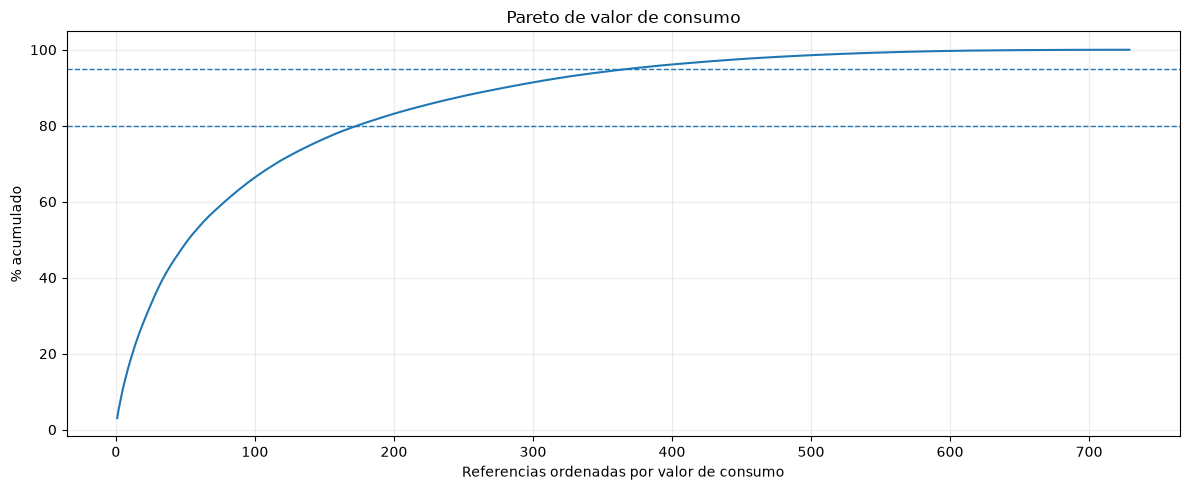

In [12]:
# Pareto de valor de consumo (solo referencias con valor positivo).
df_pareto = df.loc[df["Valor Consumo"] > 0].sort_values("Valor Consumo", ascending=False).copy()
if not df_pareto.empty:
    df_pareto["Acumulado Pareto"] = df_pareto["Valor Consumo"].cumsum() / df_pareto["Valor Consumo"].sum()
    fig, ax1 = plt.subplots(figsize=(12, 5))
    ax1.plot(np.arange(1, len(df_pareto) + 1), df_pareto["Acumulado Pareto"] * 100)
    ax1.axhline(80, linestyle="--", linewidth=1)
    ax1.axhline(95, linestyle="--", linewidth=1)
    ax1.set_xlabel("Referencias ordenadas por valor de consumo")
    ax1.set_ylabel("% acumulado")
    ax1.set_title("Pareto de valor de consumo")
    ax1.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

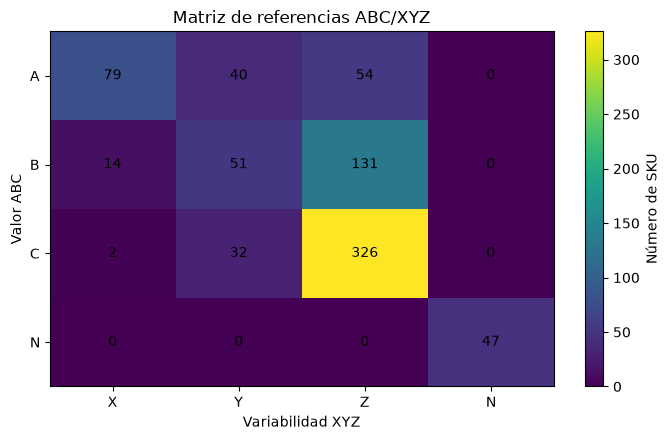

In [13]:
fig, ax = plt.subplots(figsize=(7, 4.5))
mat = pd.crosstab(df["ABC"], df["XYZ"]).reindex(
    index=["A", "B", "C", "N"], columns=["X", "Y", "Z", "N"], fill_value=0
)
im = ax.imshow(mat.to_numpy(), aspect="auto")
ax.set_xticks(range(len(mat.columns)), labels=mat.columns)
ax.set_yticks(range(len(mat.index)), labels=mat.index)
for i in range(mat.shape[0]):
    for j in range(mat.shape[1]):
        ax.text(j, i, int(mat.iloc[i, j]), ha="center", va="center")
ax.set_title("Matriz de referencias ABC/XYZ")
ax.set_xlabel("Variabilidad XYZ")
ax.set_ylabel("Valor ABC")
fig.colorbar(im, ax=ax, label="Número de SKU")
plt.tight_layout()
plt.show()

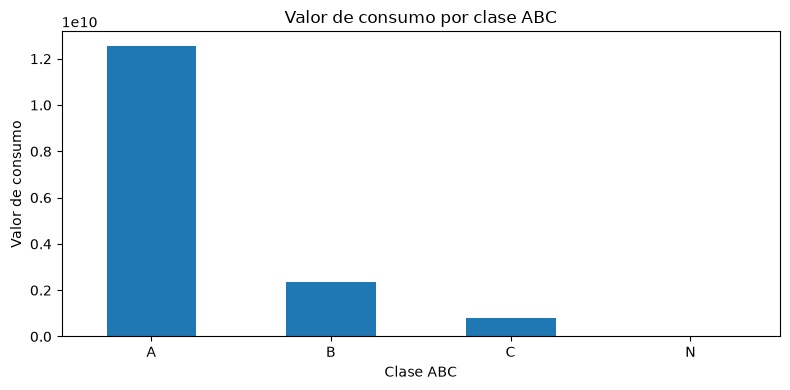

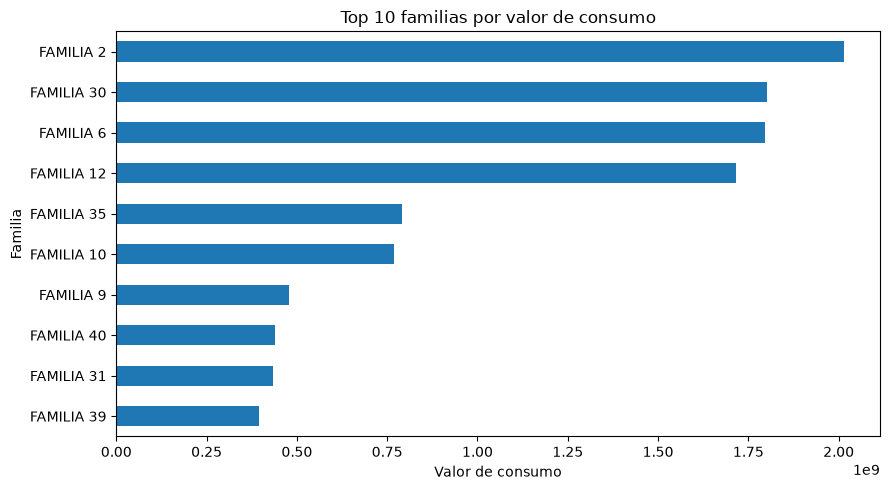

In [14]:
valor_por_abc = df.groupby("ABC")["Valor Consumo"].sum().reindex(["A", "B", "C", "N"], fill_value=0)
valor_por_abc.plot(kind="bar", figsize=(8, 4), title="Valor de consumo por clase ABC")
plt.ylabel("Valor de consumo")
plt.xlabel("Clase ABC")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

top_familias = df.groupby("Familia", dropna=False)["Valor Consumo"].sum().nlargest(10).sort_values()
top_familias.plot(kind="barh", figsize=(9, 5), title="Top 10 familias por valor de consumo")
plt.xlabel("Valor de consumo")
plt.tight_layout()
plt.show()

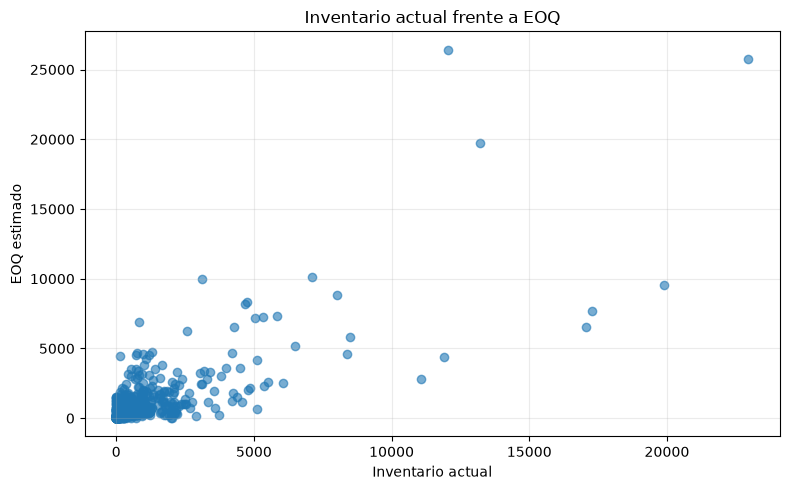

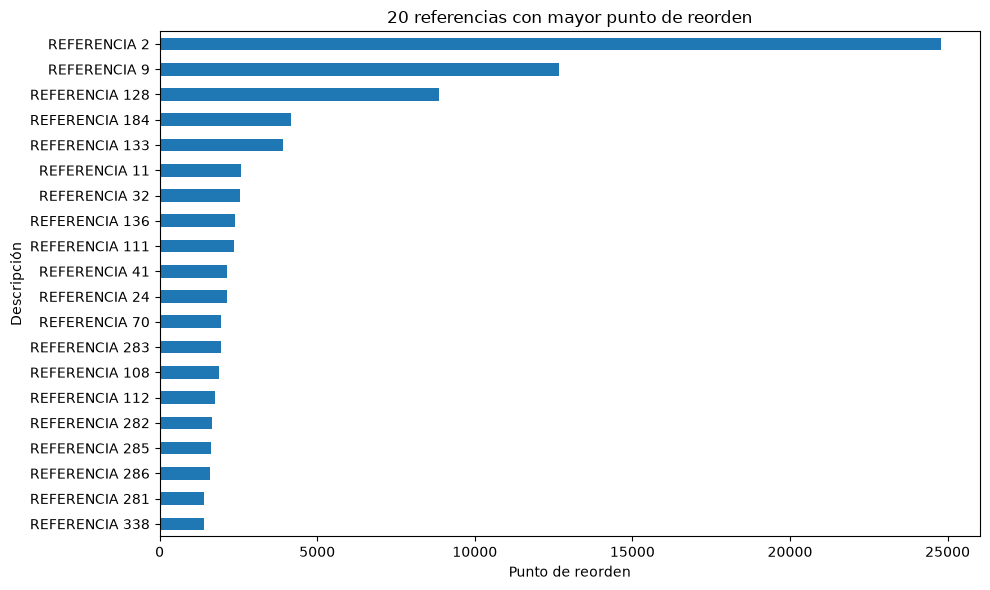

In [15]:
fig, ax = plt.subplots(figsize=(8, 5))
datos_scatter = df.dropna(subset=["Inventario", "EOQ"])
ax.scatter(datos_scatter["Inventario"], datos_scatter["EOQ"], alpha=0.6)
ax.set_xlabel("Inventario actual")
ax.set_ylabel("EOQ estimado")
ax.set_title("Inventario actual frente a EOQ")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

top_reorden = df.nlargest(20, "Punto Reorden").sort_values("Punto Reorden")
top_reorden.plot(
    x="Descripción", y="Punto Reorden", kind="barh", figsize=(10, 6),
    legend=False, title="20 referencias con mayor punto de reorden"
)
plt.xlabel("Punto de reorden")
plt.tight_layout()
plt.show()

## 8. Análisis de ubicaciones (opcional)

Si existe `data/raw/ubicaciones.csv`, se generan vistas superior, vertical y un **mapa 3D del centro de distribución**. El mapa 3D colorea y dimensiona los puntos según la prioridad ABC/XYZ; las referencias sin clasificación se muestran en gris.

In [16]:
ubicacion = None

if LOCATIONS_FILE.is_file():
    ubicacion_raw = pd.read_csv(LOCATIONS_FILE, sep=";", encoding="utf-8-sig")
    ubicacion_raw.columns = ubicacion_raw.columns.astype(str).str.strip()
    requeridas_ubicacion = {"SKU", "X", "Y", "Z"}
    faltantes_ubicacion = requeridas_ubicacion - set(ubicacion_raw.columns)

    if faltantes_ubicacion:
        warnings.warn(
            "No se procesa ubicaciones.csv; faltan columnas: "
            + ", ".join(sorted(faltantes_ubicacion))
        )
    else:
        ubicacion = ubicacion_raw.copy()
        for col in ["X", "Y", "Z"]:
            ubicacion[col] = pd.to_numeric(
                ubicacion[col].astype(str).str.replace(",", ".", regex=False),
                errors="coerce",
            )
        ubicacion["SKU"] = ubicacion["SKU"].astype("string").str.strip()
        ubicacion = ubicacion.drop_duplicates(subset="SKU", keep="first")

        # Normalizar claves de cruce sin cambiar el identificador original mostrado.
        mapa_clase = df[["Código", "ABCXYZ"]].copy()
        mapa_clase["Código"] = mapa_clase["Código"].astype("string").str.strip()
        ubicacion = ubicacion.merge(
            mapa_clase, left_on="SKU", right_on="Código", how="left"
        )

        prioridad = {
            "AX": 9, "AY": 8, "AZ": 7,
            "BX": 6, "BY": 5, "BZ": 4,
            "CX": 3, "CY": 2, "CZ": 1,
        }
        ubicacion["Prioridad"] = ubicacion["ABCXYZ"].map(prioridad)
        print(f"Ubicaciones procesadas: {len(ubicacion):,}")
        print(f"Ubicaciones sin clase ABCXYZ: {int(ubicacion['ABCXYZ'].isna().sum()):,}")
        display(ubicacion.head())
else:
    print(f"No se encontró archivo opcional de ubicaciones: {LOCATIONS_FILE}")

Ubicaciones procesadas: 609
Ubicaciones sin clase ABCXYZ: 0


,X,Y,Z,SKU,Código,ABCXYZ,Prioridad
0,0,0.00,0.00,449081,449081,BY,5.00
1,0,1.22,0.00,520308,520308,CZ,1.00
2,0,2.44,0.00,489773,489773,CY,2.00
3,0,3.66,0.00,450216,450216,BZ,4.00
4,0,4.88,0.00,460000,460000,BY,5.00


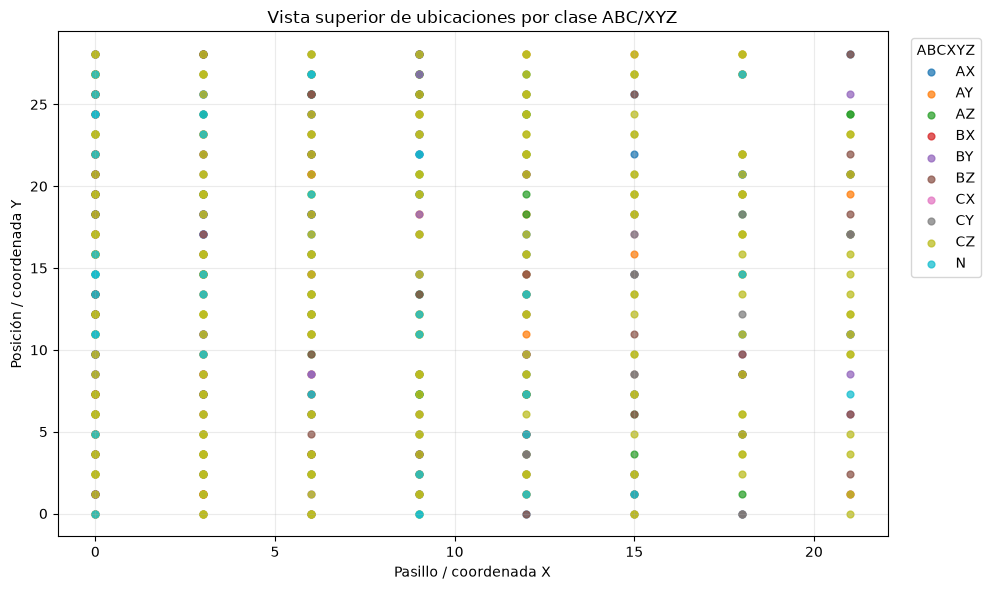

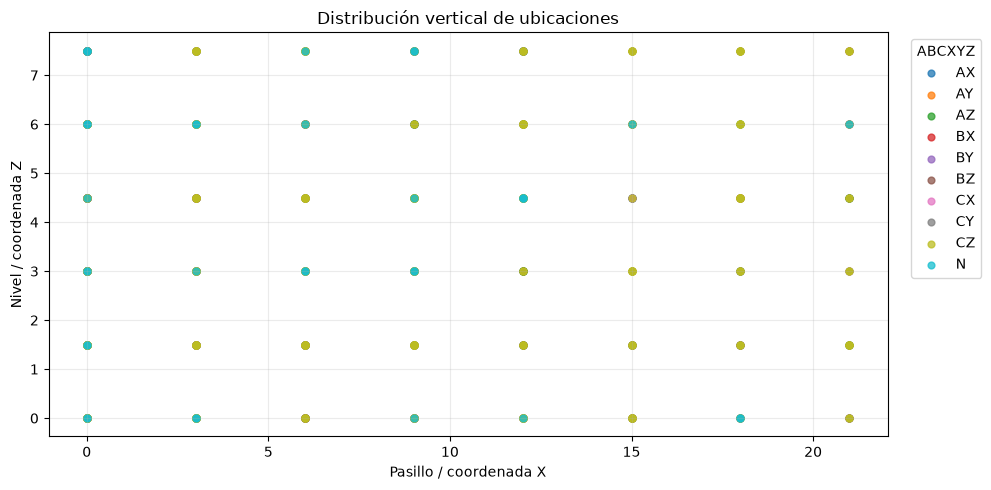

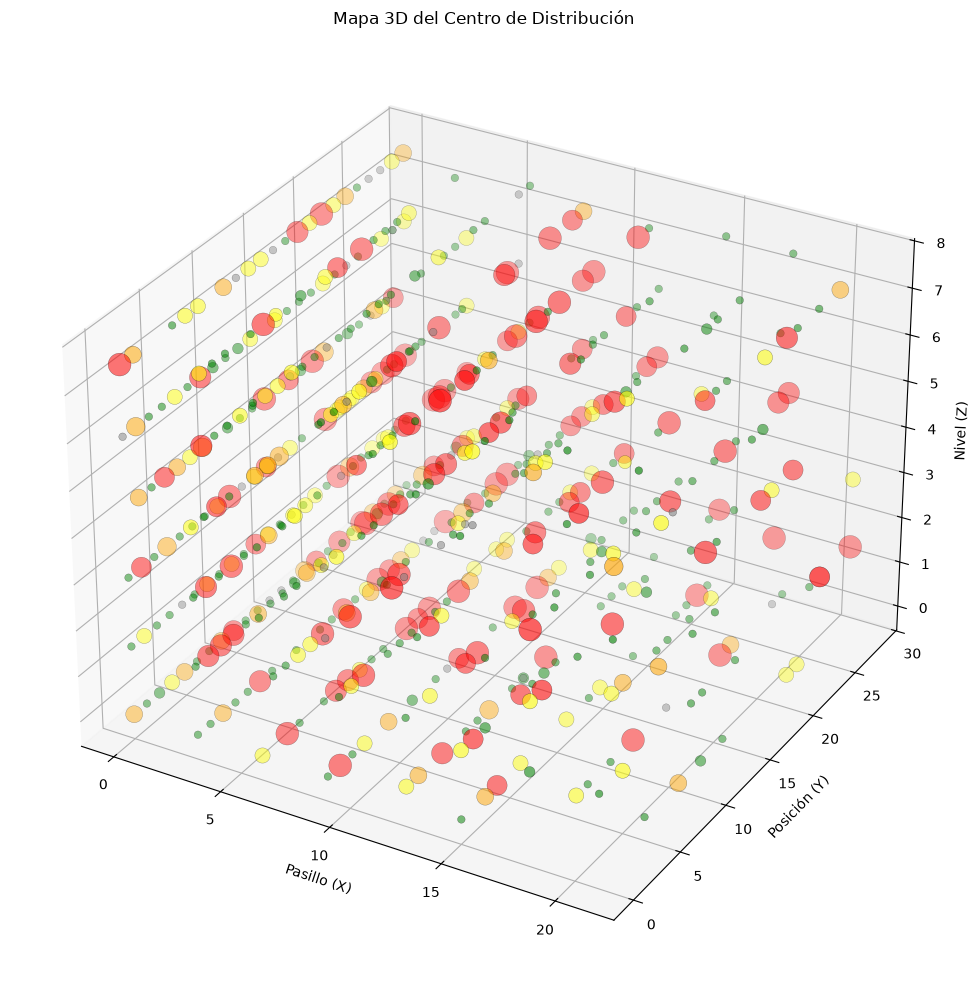

In [17]:
if ubicacion is not None and not ubicacion.empty:
    # Asignar colores por prioridad ABC/XYZ:
    # alta = rojo, media-alta = naranja, media-baja = amarillo, baja = verde.
    def color_por_prioridad(prioridad):
        if pd.isna(prioridad):
            return "gray"
        if prioridad >= 7:
            return "red"
        if prioridad >= 5:
            return "orange"
        if prioridad >= 3:
            return "yellow"
        return "green"

    ubicacion["Color"] = ubicacion["Prioridad"].apply(color_por_prioridad)
    # Evitar tamaños nulos para ubicaciones sin clasificación ABC/XYZ.
    ubicacion["PrioridadGrafico"] = (
        pd.to_numeric(ubicacion["Prioridad"], errors="coerce")
        .fillna(1)
        .clip(lower=1, upper=9)
    )

    # Vista superior: distribución de posiciones por pasillo.
    fig, ax = plt.subplots(figsize=(10, 6))
    for clase, grupo in ubicacion.groupby("ABCXYZ", dropna=False):
        ax.scatter(grupo["X"], grupo["Y"], s=24, alpha=0.75, label=str(clase))
    ax.set_xlabel("Pasillo / coordenada X")
    ax.set_ylabel("Posición / coordenada Y")
    ax.set_title("Vista superior de ubicaciones por clase ABC/XYZ")
    ax.grid(alpha=0.25)
    ax.legend(title="ABCXYZ", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    # Vista vertical: relación entre pasillo y nivel.
    fig, ax = plt.subplots(figsize=(10, 5))
    for clase, grupo in ubicacion.groupby("ABCXYZ", dropna=False):
        ax.scatter(grupo["X"], grupo["Z"], s=24, alpha=0.75, label=str(clase))
    ax.set_xlabel("Pasillo / coordenada X")
    ax.set_ylabel("Nivel / coordenada Z")
    ax.set_title("Distribución vertical de ubicaciones")
    ax.grid(alpha=0.25)
    ax.legend(title="ABCXYZ", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

    # Mapa 3D del centro de distribución.
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401; registra la proyección 3D

    fig = plt.figure(figsize=(12, 10))
    ax = fig.add_subplot(111, projection="3d")
    ax.scatter(
        ubicacion["X"],
        ubicacion["Y"],
        ubicacion["Z"],
        c=ubicacion["Color"],
        s=ubicacion["PrioridadGrafico"] * 30,
        alpha=0.8,
        edgecolors="black",
        linewidths=0.25,
    )
    ax.set_xlabel("Pasillo (X)")
    ax.set_ylabel("Posición (Y)")
    ax.set_zlabel("Nivel (Z)")
    ax.set_title("Mapa 3D del Centro de Distribución")
    ax.grid(True)
    plt.tight_layout()
    plt.show()
else:
    print(
        "No se genera el mapa de ubicaciones. Verifica que exista "
        f"{LOCATIONS_FILE} y que contenga las columnas SKU, X, Y y Z."
    )


## 9. Resumen final y exportación

In [ ]:
# Tabla final de trabajo: selección explícita de campos para el usuario operativo.
columnas_salida = [
    "Código", "Descripción", "Familia", "Grupo", "Línea",
    "Inventario", "Pedidos", "Vr Unit", "Demanda Anual",
    "Demanda Promedio", "Desv", "Valor Consumo", "ABC", "XYZ", "ABCXYZ",
    "EOQ", "Costo Mantener", "Stock Seguridad", "Punto Reorden",
    "Rotacion", "Cobertura Meses", "Estado Reposicion",
]
resultado = df[[c for c in columnas_salida if c in df.columns]].copy()

display(resultado.head(20))
print(f"Resultado final: {len(resultado):,} filas y {len(resultado.columns):,} columnas.")

In [ ]:
# Exportar en la carpeta output del proyecto.
OUTPUT_DIR = PROJECT_ROOT / "output"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

archivo_salida = OUTPUT_DIR / "inventario_procesado_eoq.csv"
resultado.to_csv(
    archivo_salida,
    index=False,
    sep=";",
    encoding="utf-8-sig",
    decimal=",",
)
print(f"Archivo exportado: {archivo_salida}")

if ubicacion is not None:
    archivo_ubicaciones = OUTPUT_DIR / "ubicaciones_clasificadas.csv"
    ubicacion.to_csv(
        archivo_ubicaciones,
        index=False,
        sep=";",
        encoding="utf-8-sig",
        decimal=",",
    )
    print(f"Ubicaciones exportadas: {archivo_ubicaciones}")

## Cierre: cómo conectar este análisis con Streamlit

La aplicación debería reutilizar la misma lógica mediante funciones en `src/` o en un módulo de motor compartido. Evita que `app.py` vuelva a implementar las fórmulas.

Navegación recomendada:
1. **Resumen ejecutivo:** KPI generales y alertas.
2. **ABC/XYZ:** distribución, matriz y filtros.
3. **EOQ y costos:** cantidad económica y análisis por clase.
4. **Reabastecimiento:** stock de seguridad, punto de reorden y SKU a revisar.
5. **Almacén:** ubicaciones y slotting, cuando exista el archivo.
6. **Datos y exportación:** tabla maestra filtrable y descargas.

### Controles antes de llevarlo a producción
- Validar unidades monetarias y la interpretación de `Costo Almacenar`.
- Confirmar el período real de demanda y la definición del nivel de servicio.
- Revisar la política para demanda nula, valores negativos y referencias sin datos.
- Comparar los resultados del notebook con una muestra revisada manualmente.
- Mantener pruebas de regresión para que los cambios no alteren los indicadores sin explicación.